# Correct Patient-Level Clinical and Risk-Factor Analysis

This notebook uses the **actual CSV structure**:

- `Patientwise_Data.csv` → patient metadata: Age, Gender, Smoking, Betel-quid chewing, Alcohol
- `Imagewise_Data.csv` → image-level clinical category and diagnosis

### Important
The letters in `Patient ID` are **never used to determine cancer status**.

Cancer/OCA status is obtained from the actual clinical information in `Imagewise_Data.csv`:
- `Category = OCA` is treated as the oral-cancer category.
- `Clinical Diagnosis` is retained for diagnosis-level analysis.

Because one patient can have multiple images, patient-level plots first remove duplicate **Patient ID + Category** combinations so that multiple images from the same category do not inflate patient counts.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

PATIENT_FILE = '/Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Patientwise_Data.csv'
IMAGE_FILE = '/Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Imagewise_Data.csv'

patient_df = pd.read_csv(PATIENT_FILE)
image_df = pd.read_csv(IMAGE_FILE)

# Clean column names
patient_df.columns = patient_df.columns.str.strip()
image_df.columns = image_df.columns.str.strip()

# Clean values
for col in ["Gender", "Smoking", "Chewing_Betel_Quid", "Alcohol"]:
    patient_df[col] = patient_df[col].astype(str).str.strip()

for col in ["Category", "Clinical Diagnosis"]:
    image_df[col] = image_df[col].astype(str).str.strip()

# IMPORTANT:
# Extract the complete patient ID from the image name.
# This does NOT determine cancer status.
# Examples:
# R-01-01 -> R-01
# N-206-01 -> N-206
# K-009-01 -> K-009
# S-68-01 -> S-68
image_df["Patient ID"] = (
    image_df["Image Name"]
    .astype(str)
    .str.extract(r"^([A-Za-z]+-\d+)-\d+$")[0]
)

print("Patientwise rows:", len(patient_df))
print("Unique patients in Patientwise_Data:", patient_df["Patient ID"].nunique())
print("Images:", len(image_df))
print("Unique patients represented in Imagewise_Data:", image_df["Patient ID"].nunique())

print("\nImage-level clinical categories:")
print(image_df["Category"].value_counts())

print("\nImage-level clinical diagnoses:")
print(image_df["Clinical Diagnosis"].value_counts())

Patientwise rows: 714
Unique patients in Patientwise_Data: 714
Images: 3000
Unique patients represented in Imagewise_Data: 672

Image-level clinical categories:
Category
OPMD       1394
Benign      748
Healthy     729
OCA         129
Name: count, dtype: int64

Image-level clinical diagnoses:
Clinical Diagnosis
Normal Mucosa         728
OSF                   684
OLP                   358
Oral Cancer           125
VBD                   123
                     ... 
Early Leukoplakia       1
Verucouss Ca            1
Allergic Reaction       1
Mucosil                 1
Alevolar Keratosis      1
Name: count, Length: 149, dtype: int64


## 1. Convert image-level categories to patient-level categories

A patient may have many images. For example, if one patient has 5 OPMD images, that patient should count as **1 OPMD patient**, not 5.

We therefore keep unique `Patient ID + Category` combinations.

In [4]:
patient_category = (
    image_df[["Patient ID", "Category"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

category_order = ["Healthy", "Benign", "OPMD", "OCA"]

category_counts = (
    patient_category["Category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

print("Patient counts by clinical category:")
print(category_counts)

print("\nNumber of unique OCA patients:",
      patient_category.loc[
          patient_category["Category"].eq("OCA"),
          "Patient ID"
      ].nunique())

Patient counts by clinical category:
Category
Healthy    218
Benign     273
OPMD       332
OCA         61
Name: count, dtype: int64

Number of unique OCA patients: 61


## 2. Patient-level distribution of the four clinical categories

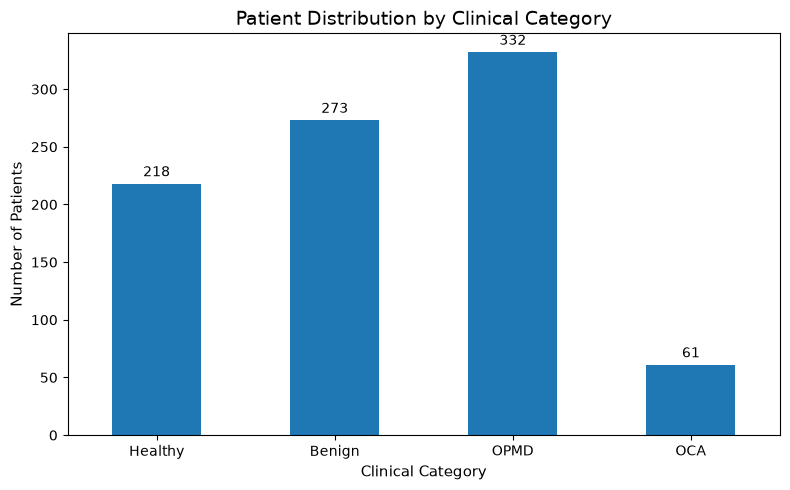

In [5]:
ax = category_counts.plot(kind="bar", figsize=(8, 5))

ax.set_title("Patient Distribution by Clinical Category")
ax.set_xlabel("Clinical Category")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

## 3. Merge patient metadata with clinical categories

This merge is performed using the **actual Patient ID**. The ID letters are only used to match the same patient across the two CSV files; they are not interpreted as cancer/non-cancer labels.

In [6]:
plot_df = patient_df.merge(
    patient_category,
    on="Patient ID",
    how="inner"
)

print("Rows after patient-category merge:", len(plot_df))
print("Unique patients in merged data:",
      plot_df["Patient ID"].nunique())

print("\nUnique patients represented by each category:")
print(
    plot_df.groupby("Category")["Patient ID"]
    .nunique()
    .reindex(category_order, fill_value=0)
)

Rows after patient-category merge: 882
Unique patients in merged data: 672

Unique patients represented by each category:
Category
Healthy    217
Benign     272
OPMD       332
OCA         61
Name: Patient ID, dtype: int64


## 4. Gender vs clinical category — patient level

Category  Healthy  Benign  OPMD  OCA
Gender                              
F              97     107   129   26
M             120     165   203   35


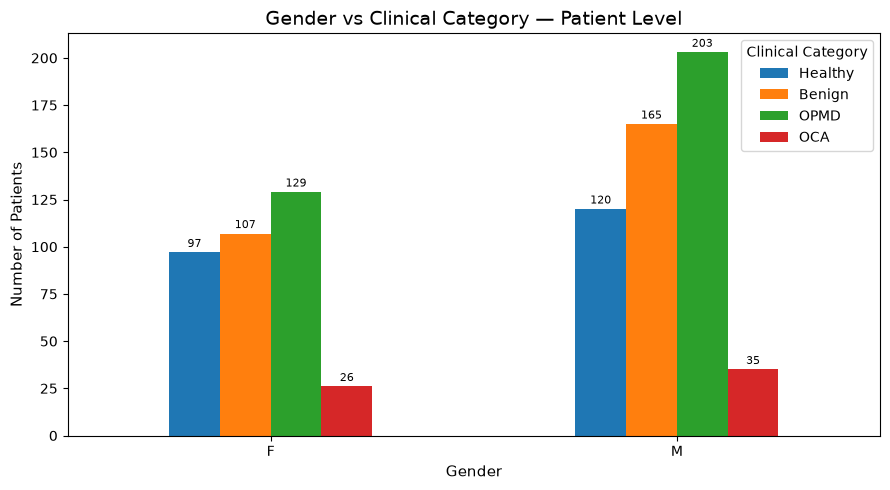

In [7]:
def make_category_plot(df, metadata_col, title):
    temp = df[["Patient ID", metadata_col, "Category"]].drop_duplicates()

    table = pd.crosstab(
        temp[metadata_col],
        temp["Category"]
    ).reindex(columns=category_order, fill_value=0)

    print(table)

    ax = table.plot(kind="bar", figsize=(9, 5))

    ax.set_title(title)
    ax.set_xlabel(metadata_col)
    ax.set_ylabel("Number of Patients")
    plt.xticks(rotation=0)
    ax.legend(title="Clinical Category")

    for container in ax.containers:
        ax.bar_label(container, padding=2, fontsize=8)

    plt.tight_layout()
    plt.show()

    return table

gender_table = make_category_plot(
    plot_df,
    "Gender",
    "Gender vs Clinical Category — Patient Level"
)

## 5. Smoking vs clinical category — patient level

Category  Healthy  Benign  OPMD  OCA
Smoking                             
No            202     249   294   50
Yes            15      23    38   11


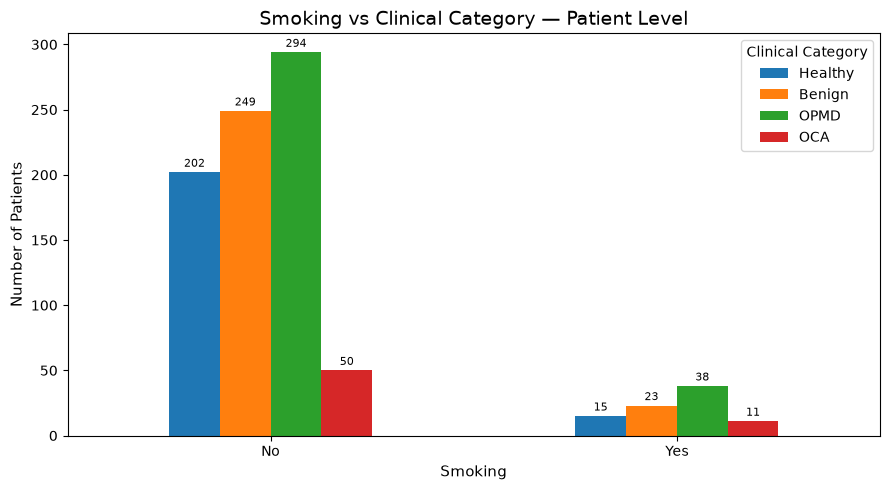

In [8]:
smoking_table = make_category_plot(
    plot_df,
    "Smoking",
    "Smoking vs Clinical Category — Patient Level"
)

## 6. Betel-quid chewing vs clinical category — patient level

Category            Healthy  Benign  OPMD  OCA
Chewing_Betel_Quid                            
No                      170     223   146   20
Yes                      47      49   186   41


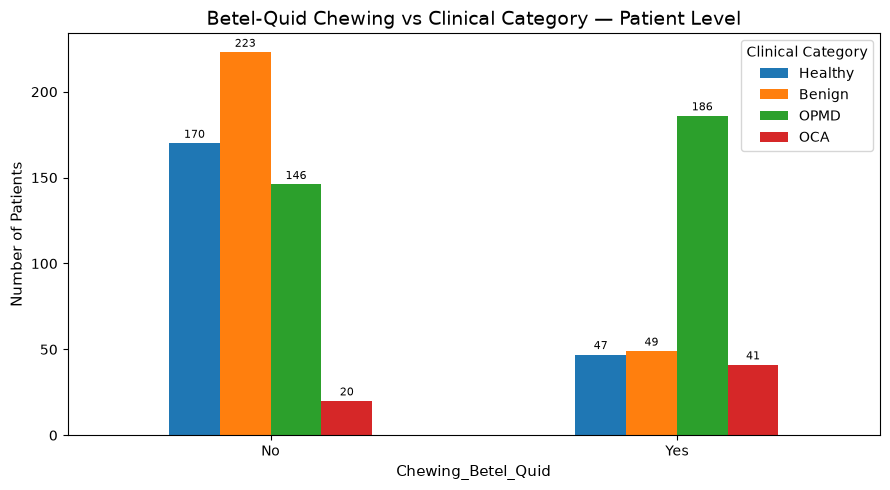

In [9]:
betel_table = make_category_plot(
    plot_df,
    "Chewing_Betel_Quid",
    "Betel-Quid Chewing vs Clinical Category — Patient Level"
)

## 7. Alcohol vs clinical category — patient level

Category  Healthy  Benign  OPMD  OCA
Alcohol                             
No            205     257   297   53
Yes            12      15    35    8


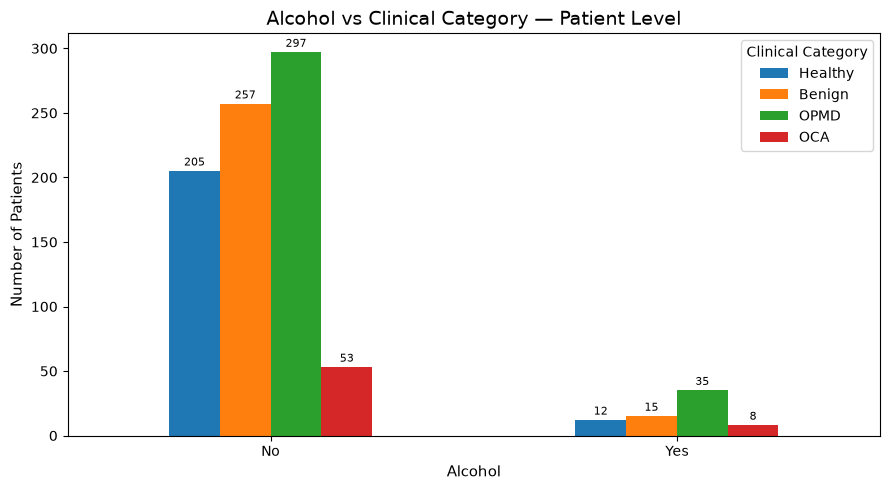

In [10]:
alcohol_table = make_category_plot(
    plot_df,
    "Alcohol",
    "Alcohol vs Clinical Category — Patient Level"
)

## 8. Cancer vs non-cancer — patient level

For a binary cancer analysis, we derive the patient's status from the **CSV clinical category**, not from the Patient ID.

A patient is marked **Cancer/OCA** if at least one of their images has `Category = OCA`.

This is appropriate for a patient-level cancer-risk-factor plot, but note that some patients can have both OCA and non-OCA images.

In [11]:
oca_patient_ids = set(
    image_df.loc[
        image_df["Category"].eq("OCA"),
        "Patient ID"
    ].dropna().unique()
)

cancer_patient_df = patient_df.copy()

cancer_patient_df["Cancer Status"] = np.where(
    cancer_patient_df["Patient ID"].isin(oca_patient_ids),
    "Cancer (OCA)",
    "Non-cancer"
)

print("Unique cancer/OCA patients:",
      (cancer_patient_df["Cancer Status"] == "Cancer (OCA)").sum())

print("\nCancer-status counts:")
print(cancer_patient_df["Cancer Status"].value_counts())

Unique cancer/OCA patients: 61

Cancer-status counts:
Cancer Status
Non-cancer      653
Cancer (OCA)     61
Name: count, dtype: int64


## 9. Smoking vs cancer — patient level

Cancer Status  Non-cancer  Cancer (OCA)
Smoking                                
No                    586            50
Yes                    67            11


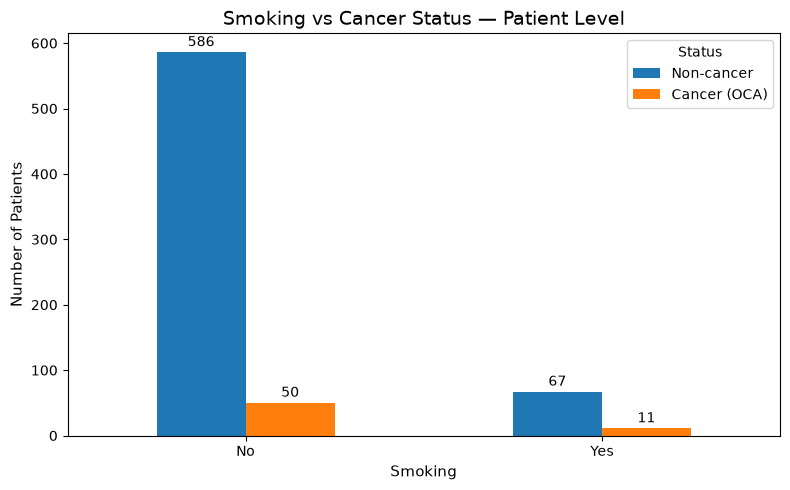

In [12]:
table = pd.crosstab(
    cancer_patient_df["Smoking"],
    cancer_patient_df["Cancer Status"]
).reindex(columns=["Non-cancer", "Cancer (OCA)"], fill_value=0)

print(table)

ax = table.plot(kind="bar", figsize=(8, 5))
ax.set_title("Smoking vs Cancer Status — Patient Level")
ax.set_xlabel("Smoking")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)
ax.legend(title="Status")

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.tight_layout()
plt.show()

## 10. Betel-quid chewing vs cancer — patient level

Cancer Status       Non-cancer  Cancer (OCA)
Chewing_Betel_Quid                          
No                         435            20
Yes                        218            41


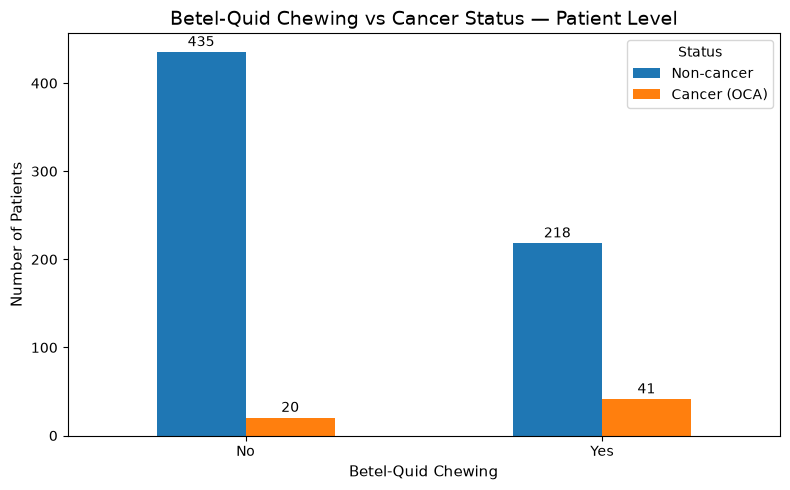

In [13]:
table = pd.crosstab(
    cancer_patient_df["Chewing_Betel_Quid"],
    cancer_patient_df["Cancer Status"]
).reindex(columns=["Non-cancer", "Cancer (OCA)"], fill_value=0)

print(table)

ax = table.plot(kind="bar", figsize=(8, 5))
ax.set_title("Betel-Quid Chewing vs Cancer Status — Patient Level")
ax.set_xlabel("Betel-Quid Chewing")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)
ax.legend(title="Status")

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.tight_layout()
plt.show()

## 11. Alcohol vs cancer — patient level

Cancer Status  Non-cancer  Cancer (OCA)
Alcohol                                
No                    600            53
Yes                    53             8


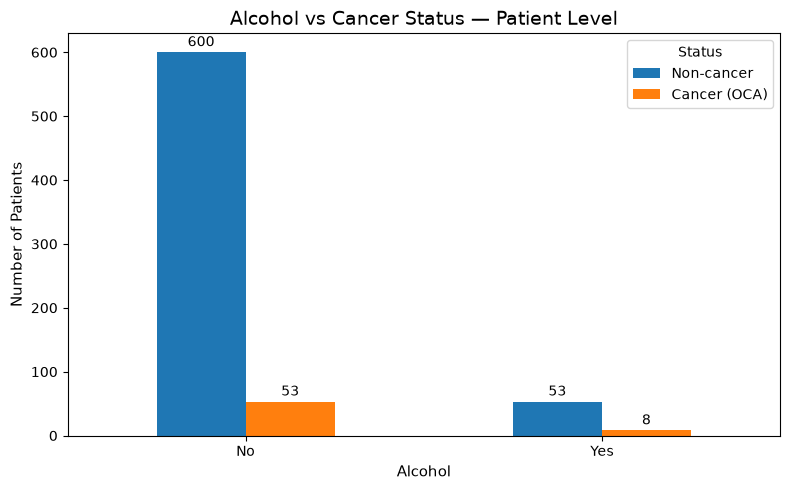

In [14]:
table = pd.crosstab(
    cancer_patient_df["Alcohol"],
    cancer_patient_df["Cancer Status"]
).reindex(columns=["Non-cancer", "Cancer (OCA)"], fill_value=0)

print(table)

ax = table.plot(kind="bar", figsize=(8, 5))
ax.set_title("Alcohol vs Cancer Status — Patient Level")
ax.set_xlabel("Alcohol")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)
ax.legend(title="Status")

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.tight_layout()
plt.show()

## 12. Gender vs cancer — patient level

Cancer Status  Non-cancer  Cancer (OCA)
Gender                                 
F                     268            26
M                     385            35


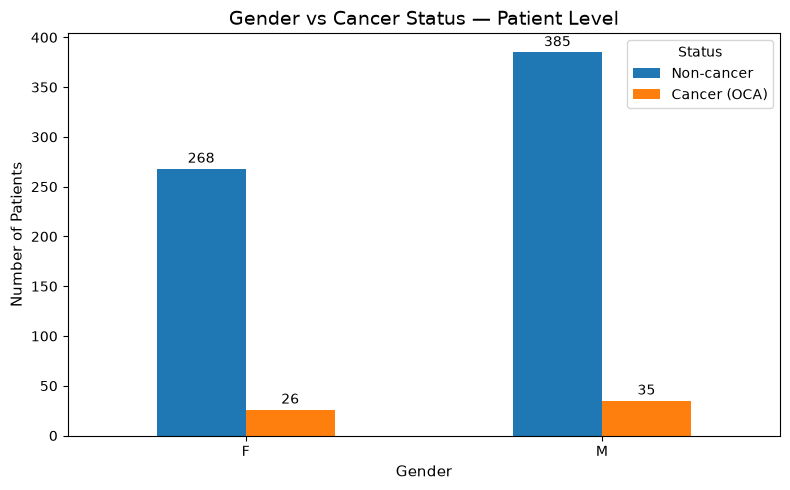

In [15]:
table = pd.crosstab(
    cancer_patient_df["Gender"],
    cancer_patient_df["Cancer Status"]
).reindex(columns=["Non-cancer", "Cancer (OCA)"], fill_value=0)

print(table)

ax = table.plot(kind="bar", figsize=(8, 5))
ax.set_title("Gender vs Cancer Status — Patient Level")
ax.set_xlabel("Gender")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=0)
ax.legend(title="Status")

for container in ax.containers:
    ax.bar_label(container, padding=2)

plt.tight_layout()
plt.show()

## 13. Clinical diagnosis — unique patient counts

This provides a more detailed view of the actual `Clinical Diagnosis` field in the CSV.

Again, a patient is counted once for each diagnosis they have, regardless of how many images they have.

Clinical Diagnosis
Normal Mucosa           216
OSF                     132
OLP                      96
Oral Cancer              58
Leukoplakia              36
                       ... 
Hairy Tongue / VBD        1
Haematoma                 1
Haemangioma               1
Gliosis + Pale Mucos      1
White Coated Tongue       1
Name: Patient ID, Length: 149, dtype: int64


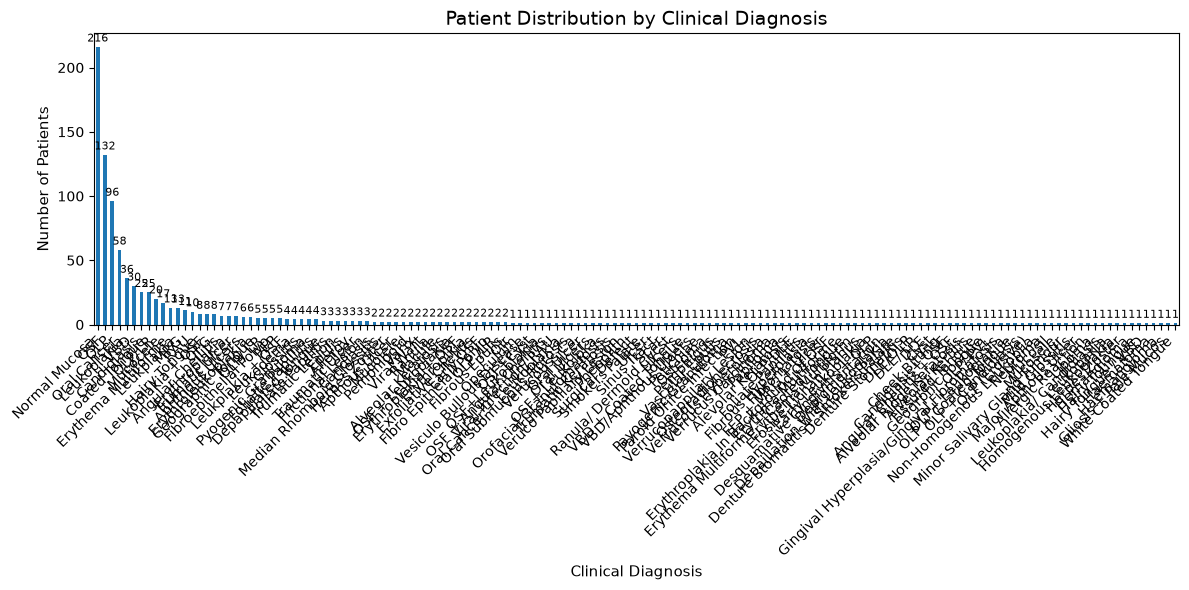

In [16]:
patient_diagnosis = (
    image_df[["Patient ID", "Clinical Diagnosis"]]
    .drop_duplicates()
)

diagnosis_counts = (
    patient_diagnosis
    .groupby("Clinical Diagnosis")["Patient ID"]
    .nunique()
    .sort_values(ascending=False)
)

print(diagnosis_counts)

ax = diagnosis_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Patient Distribution by Clinical Diagnosis")
ax.set_xlabel("Clinical Diagnosis")
ax.set_ylabel("Number of Patients")
plt.xticks(rotation=45, ha="right")

for container in ax.containers:
    ax.bar_label(container, padding=2, fontsize=8)

plt.tight_layout()
plt.show()

# Important interpretation

1. **Patient ID letters are not cancer indicators.** They are used only to link an image to its patient.
2. `Category = OCA` is used to identify OCA in the binary cancer analysis because this is the clinical category present in the image CSV.
3. The four clinical-category patient counts are **not necessarily mutually exclusive** because one patient can have images from multiple categories.
4. Multiple images from one patient are not counted repeatedly within the same category.
5. These graphs show **dataset distribution/association** and do not prove causation.
6. If another file or analysis reports a different number of cancer patients (for example, 20), that number must come from a different filtering/labeling rule or subset. It should not be forced into this analysis without identifying that rule.